<a href="https://colab.research.google.com/github/valois-sirait/indobert-absa-model-training/blob/main/indobert_absa_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **AKUISISI DATA**

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/dataset_Google-Maps-Reviews-Scraper_2025-12-02_08-33-21-567.csv')
df.columns

Index(['title', 'url', 'stars', 'name', 'reviewUrl', 'text'], dtype='object')

In [ ]:
df.head()

,title,url,stars,name,reviewUrl,text
0,Rumah Makan BPK Tesalonika,https://www.google.com/maps/search/?api=1&quer...,1,NaN,NaN,NaN
1,Rumah Makan BPK Tesalonika,https://www.google.com/maps/search/?api=1&quer...,5,NaN,NaN,NaN
2,Rumah Makan BPK Tesalonika,https://www.google.com/maps/search/?api=1&quer...,5,NaN,NaN,NaN
3,Rumah Makan BPK Tesalonika,https://www.google.com/maps/search/?api=1&quer...,5,NaN,NaN,Nikmat dan memuaskan banget 😍😍😍😍😚 selalu ingin...
4,Rumah Makan BPK Tesalonika,https://www.google.com/maps/search/?api=1&quer...,5,NaN,NaN,mantap bosku\nluarbiasa\n❤️❤️❤️


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4125 entries, 0 to 4124
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   title      4125 non-null   object 
 1   url        4125 non-null   object 
 2   stars      4125 non-null   int64  
 3   name       0 non-null      float64
 4   reviewUrl  0 non-null      float64
 5   text       1784 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 193.5+ KB


In [ ]:
df.isnull().sum()

,0
title,0
url,0
stars,0
name,4125
reviewUrl,4125
text,2341


Seleksi Data, menghapus data kosong/null

In [ ]:
df = df[['text']]
df = df.dropna(subset=['text'])
df = df[df['text'].str.strip() != ""]
df.sample(10)

,text
1319,Packing untuk dibawa dalam pesawat cukup rapi ...
3904,Makanan enak
2937,Rasa bpkny sangat munggugah selera
2329,Rumah makan. Non halal yang enak
1775,Hanya ingin memuaskan rasa ingin tahu saja.\nT...
10,Lezat seperti biasa
2602,Iga babinya joosss
938,"Makanannya enak,kebersihan perlu ditingkatkan,..."
88,Panggang B2 nya enak dan sambal nya juga enak ...
2465,Tak ada yang tak kenal tempat ini.RM b2 yg ena...


In [ ]:
len(df)

1784

Simpan Data

In [ ]:
df.to_csv('/content/clean_raw_data_bpk_tesalonika.csv', index=False)

# **PREPROCESING DATA**

**1.   Cleaning Data**


In [ ]:
import re

def clean_text(text):
    if not isinstance(text, str): return ""
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^\w\s\.,!\?]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("--- Sample Sebelum Cleaning ---")
display(df['text'].head())

df['text'] = df['text'].apply(clean_text)

print("\n--- Sample Sesudah Cleaning ---")
display(df['text'].head())

--- Sample Sebelum Cleaning ---


,text
3,Nikmat dan memuaskan banget selalu ingin datan...
4,mantap bosku luarbiasa
7,Nyaman
8,Tempat makan BPK dengan rasa menu lezat. Harga...
9,Bersih dan parkiran luas



--- Sample Sesudah Cleaning ---


,text
3,Nikmat dan memuaskan banget selalu ingin datan...
4,mantap bosku luarbiasa
7,Nyaman
8,Tempat makan BPK dengan rasa menu lezat. Harga...
9,Bersih dan parkiran luas


**2. Data Normalization**

Normalisasi elongation (huruf berulang) dan pemetaan slang menggunakan dataset Hugging Face.



In [ ]:
from datasets import load_dataset
import re

# Load slang dictionary
print("Memuat kamus slang...")
ds = load_dataset("zeroix07/indo-slang-words")

slang_dict = {}

for row in ds['train']['text']:
    if ':' in row:
        parts = row.split(':', 1)
        slang_dict[parts[0].strip()] = parts[1].strip()

# Menghapus kata tertentu dari kamus slang
# agar tidak salah normalisasi pada konteks domain dataset

excluded_words = ['bpk', 'karo', 'kidu']

for word in excluded_words:
    if word in slang_dict:
        del slang_dict[word]

def normalize_text(text):

    # Elongation normalization
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    words = text.split()
    normalized_words = []

    for w in words:
        w_lower = w.lower()
        normalized_word = slang_dict.get(w_lower, w)
        normalized_words.append(normalized_word)

    return ' '.join(normalized_words)

print("--- Sample Sebelum Normalisasi ---")
display(df['text'].head())

df['text'] = df['text'].apply(normalize_text)

print("\n--- Sample Sesudah Normalisasi ---")
display(df['text'].head())

Memuat kamus slang...
--- Sample Sebelum Normalisasi ---


,text
3,Nikmat dan memuaskan banget selalu ingin datan...
4,mantap bosku luar biasa
7,Nyaman
8,Tempat makan BPK dengan rasa menu lezat. Harga...
9,Bersih dan parkiran luas



--- Sample Sesudah Normalisasi ---


,text
3,Nikmat dan memuaskan banget selalu ingin datan...
4,mantap bosku luar biasa
7,Nyaman
8,Tempat makan BPK dengan rasa menu lezat. Harga...
9,Bersih dan parkiran luas


**3. Filtering Data**

Filtering akhir dataset: menghapus empty string, teks sangat pendek (<3 karakter) dan duplikasi data

In [ ]:
initial_count = len(df)

# Filter panjang karakter < 3
df = df[df['text'].str.len() >= 3]
# Filter duplikasi
df = df.drop_duplicates(subset=['text'])

final_count = len(df)
print(f"Data awal: {initial_count}")
print(f"Data akhir: {final_count}")
print(f"Data terbuang: {initial_count - final_count}")
display(df.sample(10))

Data awal: 1784
Data akhir: 1493
Data terbuang: 291


,text
203,Semua makanannya enak.. harganya juga ramah di...
1757,"Makanan enak, pelayanan cepat dan harga terjan..."
2126,Enak.. cuma tempat nya kurang nyaman
1916,tempat bersih.. rasa biasa saja
1402,"Tasty pork, the cut is quite thick, service is..."
1215,memuaskan
2925,Mntap
1259,Luas
1526,"Semua nya enakk, cuma rasa kuah sop nya agak a..."
1220,sangat nice grilled minced pork.


Data Understanding


--- Statistik Deskriptif Panjang Teks dan Jumlah Kata ---
       text_length   word_count
count  1493.000000  1493.000000
mean     65.454119    10.318821
std     113.312754    17.685710
min       3.000000     1.000000
25%      16.000000     3.000000
50%      32.000000     5.000000
75%      65.000000    10.000000
max    1554.000000   256.000000

Rata-rata panjang teks: 65.45 karakter
Rata-rata jumlah kata: 10.32 kata


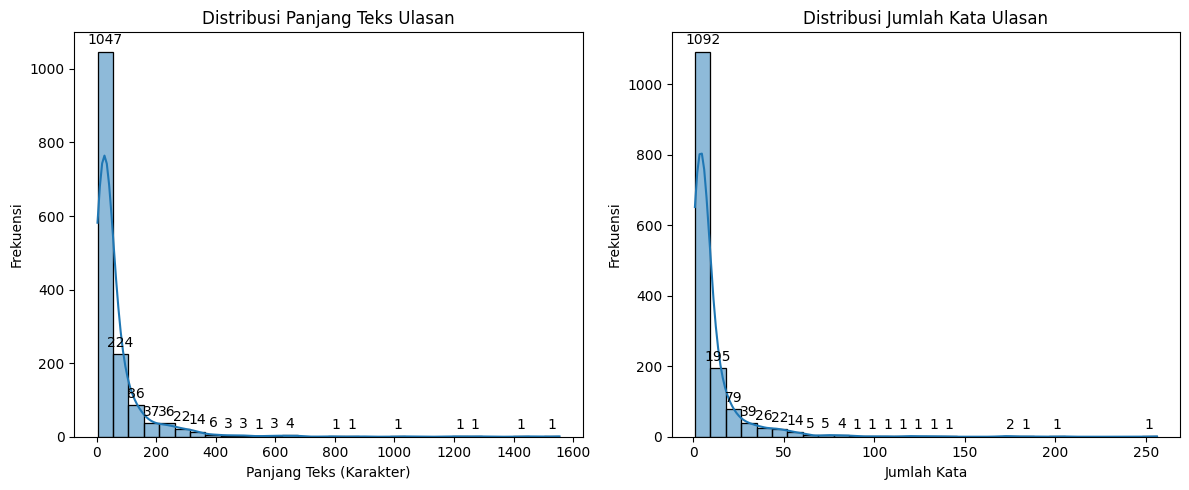

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Calculate text length and word count
df['text_length'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

# Display descriptive statistics
print("\n--- Statistik Deskriptif Panjang Teks dan Jumlah Kata ---")
print(df[['text_length', 'word_count']].describe())

# Calculate and print average text length and word count
avg_text_length = df['text_length'].mean()
avg_word_count = df['word_count'].mean()

print(f"\nRata-rata panjang teks: {avg_text_length:.2f} karakter")
print(f"Rata-rata jumlah kata: {avg_word_count:.2f} kata")

# Visualisasi distribusi panjang teks
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
ax1 = sns.histplot(df['text_length'], bins=30, kde=True)
plt.title('Distribusi Panjang Teks Ulasan')
plt.xlabel('Panjang Teks (Karakter)')
plt.ylabel('Frekuensi')
# Add frequency labels on top of bars
for patch in ax1.patches:
    height = patch.get_height()
    if height > 0: # Only label bars with height > 0
        ax1.annotate(f'{int(height)}',
                     xy=(patch.get_x() + patch.get_width() / 2, height),
                     xytext=(0, 3), # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom')

# Visualisasi distribusi jumlah kata
plt.subplot(1, 2, 2)
ax2 = sns.histplot(df['word_count'], bins=30, kde=True)
plt.title('Distribusi Jumlah Kata Ulasan')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
# Add frequency labels on top of bars
for patch in ax2.patches:
    height = patch.get_height()
    if height > 0: # Only label bars with height > 0
        ax2.annotate(f'{int(height)}',
                     xy=(patch.get_x() + patch.get_width() / 2, height),
                     xytext=(0, 3), # 3 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom')

plt.tight_layout()
plt.show()

Simpan Data Hasil Preprocesing

In [ ]:
output_file = '/content/preprocessed_data_bpk_tesalonika.csv'
df.to_csv(output_file, index=False)
print(f"Data berhasil disimpan ke: {output_file}")

Data berhasil disimpan ke: /content/preprocessed_data_bpk_tesalonika.csv


# **LABELING DATA**

In [ ]:
import pandas as pd
df = pd.read_csv('/content/data_bpk_tesalonika_labeled_gabungan_transformed.csv')
df.head()

,text,aspect,aspect_label,sentiment_label
0,Nikmat dan memuaskan banget selalu ingin datan...,makanan,1,2
1,Nikmat dan memuaskan banget selalu ingin datan...,pelayanan,0,-1
2,Nikmat dan memuaskan banget selalu ingin datan...,suasana,0,-1
3,Nikmat dan memuaskan banget selalu ingin datan...,harga,0,-1
4,Nikmat dan memuaskan banget selalu ingin datan...,lokasi,0,-1


In [ ]:
import pandas as pd

# Load dataset langsung dari file di Colab
df_transformed = pd.read_csv('/content/data_bpk_tesalonika_labeled_gabungan_transformed.csv')

# Cek kolom (opsional, untuk validasi awal)
print("Kolom dataset:", df_transformed.columns)

# Informasi mapping label
print("\n=== INFORMASI MAPPING LABEL ===")
print("aspect_label:")
print("  0 = not mentioned (tidak ada aspek)")
print("  1 = mentioned (aspek disebutkan)")

print("\nsentiment_label:")
print("  -1 = non-aspect (diabaikan pada loss function)")
print("   0 = negative")
print("   1 = neutral")
print("   2 = positive")

# Hitung distribusi kombinasi aspect_label dan sentiment_label
label_counts = (
    df_transformed
    .groupby(['aspect_label', 'sentiment_label'])
    .size()
    .unstack(fill_value=0)
)

print("\nJumlah data untuk setiap kombinasi aspect_label dan sentiment_label:")
print(label_counts)

Kolom dataset: Index(['text', 'aspect', 'aspect_label', 'sentiment_label'], dtype='object')

=== INFORMASI MAPPING LABEL ===
aspect_label:
  0 = not mentioned (tidak ada aspek)
  1 = mentioned (aspek disebutkan)

sentiment_label:
  -1 = non-aspect (diabaikan pada loss function)
   0 = negative
   1 = neutral
   2 = positive

Jumlah data untuk setiap kombinasi aspect_label dan sentiment_label:
sentiment_label    -1    0    1     2
aspect_label                         
0                3595    0    0     0
1                   0  416  189  1200


Menampilkan Distribusi Data untuk Tugas Deteksi Aspek

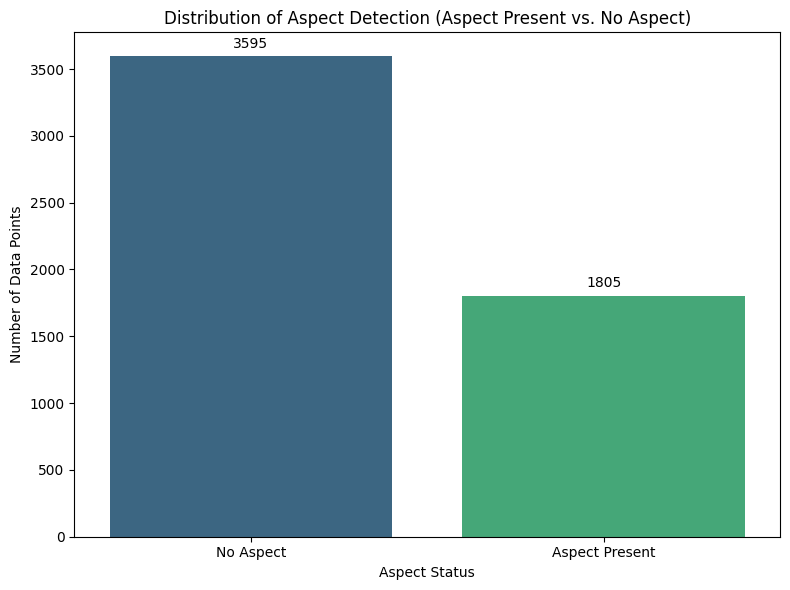

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung jumlah kemunculan aspect_label
aspect_counts = df_transformed['aspect_label'].value_counts().sort_index()

# Petakan label numerik ke label yang lebih deskriptif
aspect_labels_map = {0: 'No Aspect', 1: 'Aspect Present'}
aspect_counts.index = aspect_counts.index.map(aspect_labels_map)

plt.figure(figsize=(8, 6))
ax = sns.barplot(x=aspect_counts.index, y=aspect_counts.values, hue=aspect_counts.index, palette='viridis', legend=False)

plt.title('Distribution of Aspect Detection (Aspect Present vs. No Aspect)')
plt.xlabel('Aspect Status')
plt.ylabel('Number of Data Points')
plt.xticks(rotation=0) # Pastikan label x tidak terpotong

# Tambahkan label nilai di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.tight_layout()
plt.show()

Menampilkan Distribusi Data untuk Tugas Klasifikasi Sentimen

Tabel Distribusi Sentimen per Aspek:


sentiment_label,Negative,Neutral,Positive
aspect,,,
harga,47,31,151
lokasi,45,27,91
makanan,146,51,656
pelayanan,94,37,150
suasana,84,43,152


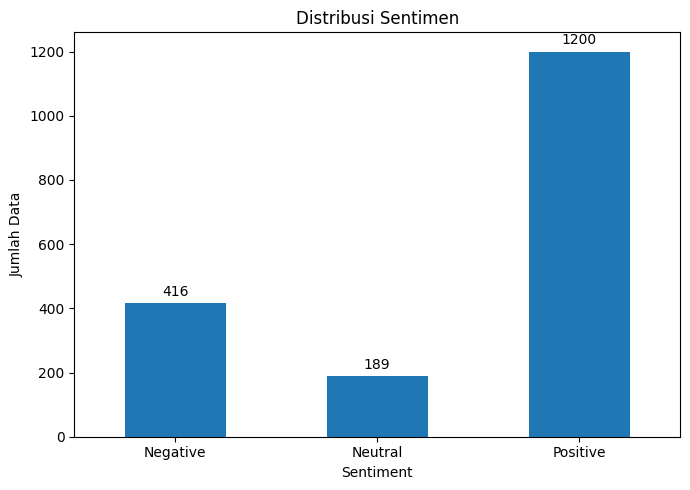

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data valid (aspect = 1, sentiment valid)
df_valid = df_transformed[
    (df_transformed['aspect_label'] == 1) &
    (df_transformed['sentiment_label'] != -1)
]

# TABEL PER-ASPEK
sentiment_table = pd.crosstab(
    df_valid['aspect'],
    df_valid['sentiment_label']
)

sentiment_table = sentiment_table.rename(columns={
    0: 'Negative',
    1: 'Neutral',
    2: 'Positive'
})

print("Tabel Distribusi Sentimen per Aspek:")
display(sentiment_table)

# GRAFIK GLOBAL SENTIMEN
sentiment_counts = df_valid['sentiment_label'].value_counts().sort_index()

sentiment_counts.index = sentiment_counts.index.map({
    0: 'Negative',
    1: 'Neutral',
    2: 'Positive'
})

ax = sentiment_counts.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Distribusi Sentimen')
plt.xlabel('Sentiment')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)

# label angka di atas bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

Menampilkan Grafik Distribuasi Sentimen Spesifik per Aspek

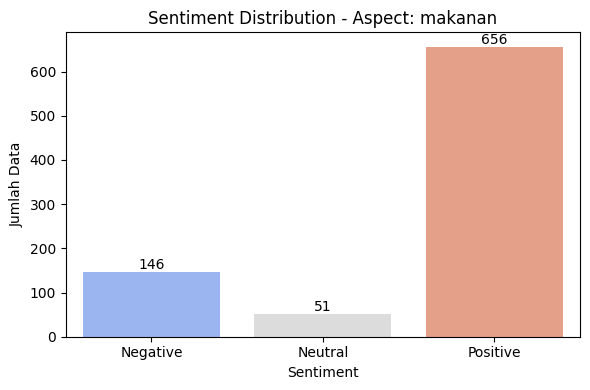

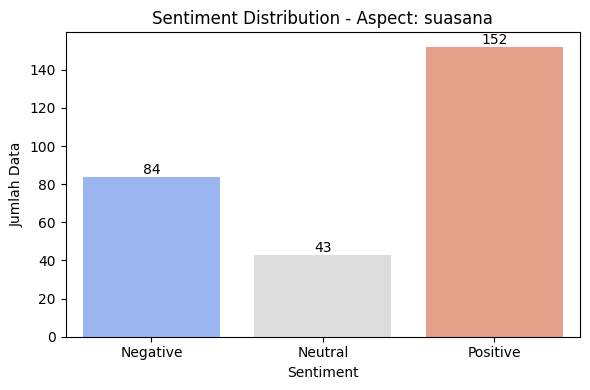

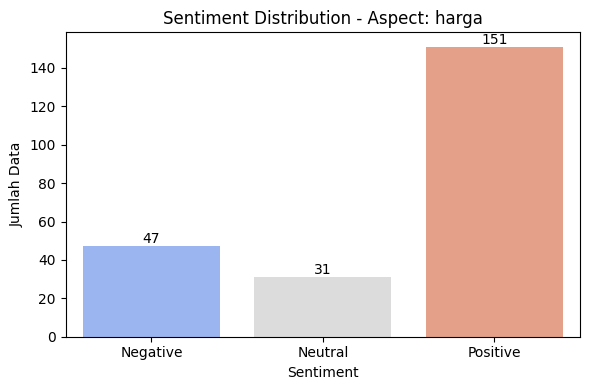

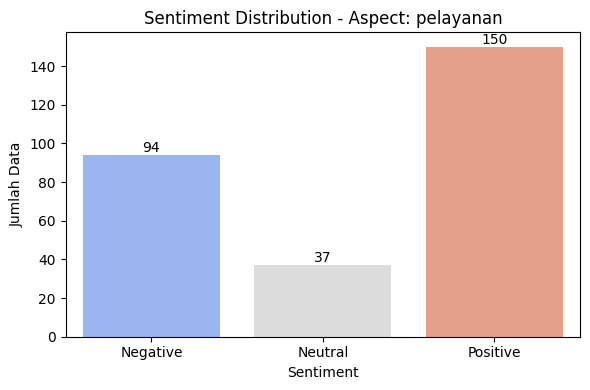

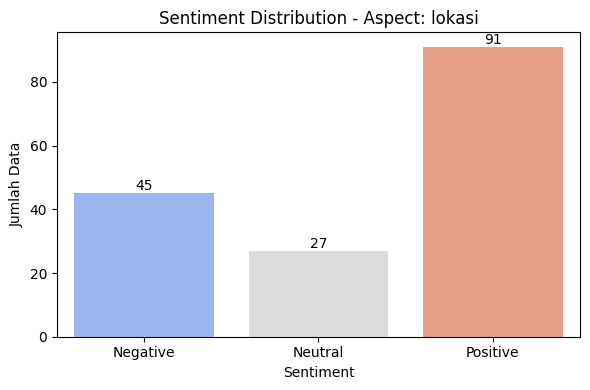

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_labels_map = {
    0: 'Negative',
    1: 'Neutral',
    2: 'Positive'
}

for aspect in df_valid['aspect'].unique():

    aspect_data = df_valid[df_valid['aspect'] == aspect]

    sentiment_counts = aspect_data['sentiment_label'].value_counts().sort_index()
    sentiment_counts.index = sentiment_counts.index.map(sentiment_labels_map)

    plt.figure(figsize=(6,4))

    sns.barplot(
        x=sentiment_counts.index,
        y=sentiment_counts.values,
        hue=sentiment_counts.index,
        palette='coolwarm',
        legend=False
    )

    plt.title(f'Sentiment Distribution - Aspect: {aspect}')
    plt.xlabel('Sentiment')
    plt.ylabel('Jumlah Data')

    # label angka di atas bar
    for i, v in enumerate(sentiment_counts.values):
        plt.text(i, v, str(v), ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

# **SPLIT DATA**

In [ ]:
import pandas as pd

# Muat dataset
df = pd.read_csv('/content/data_bpk_tesalonika_labeled_gabungan_transformed.csv')

# Tampilkan df.head() dan df.info()
print("\n--- df.head() ---")
print(df.head())

print("\n--- df.info() ---")
print(df.info())


--- df.head() ---
                                                text     aspect  aspect_label  \
0  Nikmat dan memuaskan banget selalu ingin datan...    makanan             1   
1  Nikmat dan memuaskan banget selalu ingin datan...  pelayanan             0   
2  Nikmat dan memuaskan banget selalu ingin datan...    suasana             0   
3  Nikmat dan memuaskan banget selalu ingin datan...      harga             0   
4  Nikmat dan memuaskan banget selalu ingin datan...     lokasi             0   

   sentiment_label  
0                2  
1               -1  
2               -1  
3               -1  
4               -1  

--- df.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   text             5400 non-null   object
 1   aspect           5400 non-null   object
 2   aspect_label     5400 non-null   int64 
 3   sentiment_lab

Membagi dataset menjadi data latih (80%), validasi (10%), dan pengujian (10%) berdasarkan ulasan unik untuk mencegah data leakage antar subset.

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Ambil daftar ulasan unik dari kolom 'text'
unique_reviews = df['text'].unique()
unique_reviews_df = pd.DataFrame(unique_reviews, columns=['text'])

# 2. Bagi ulasan unik ke Train, Val, dan Test (80/10/10)
train_txt, temp_txt = train_test_split(unique_reviews_df, test_size=0.2, random_state=7)
val_txt, test_txt = train_test_split(temp_txt, test_size=0.5, random_state=7)

# 3. Filter DataFrame asli berdasarkan teks yang sudah dibagi
train_df = df[df['text'].isin(train_txt['text'])].copy()
val_df = df[df['text'].isin(val_txt['text'])].copy()
test_df = df[df['text'].isin(test_txt['text'])].copy()


print(f"\nUkuran Train set: {len(train_df)} baris (dari {len(train_txt)} ulasan)")
print(f"Ukuran Validation set: {len(val_df)} baris (dari {len(val_txt)} ulasan)")
print(f"Ukuran Test set: {len(test_df)} baris (dari {len(test_txt)} ulasan)")

# 4. Cek apakah ada teks yang bocor (harusnya 0)
leakage_check = set(train_df['text']).intersection(set(test_df['text']))
print(f"\nJumlah teks ulasan yang bocor antara Train & Test: {len(leakage_check)}")

print("\n--- Distribusi aspect_label di Train set ---")
print(train_df['aspect_label'].value_counts(normalize=True))


Ukuran Train set: 4310 baris (dari 862 ulasan)
Ukuran Validation set: 540 baris (dari 108 ulasan)
Ukuran Test set: 550 baris (dari 108 ulasan)

Jumlah teks ulasan yang bocor antara Train & Test: 0

--- Distribusi aspect_label di Train set ---
aspect_label
0    0.662413
1    0.337587
Name: proportion, dtype: float64


Menampilkan Grafik Distribusi Pembagian Data

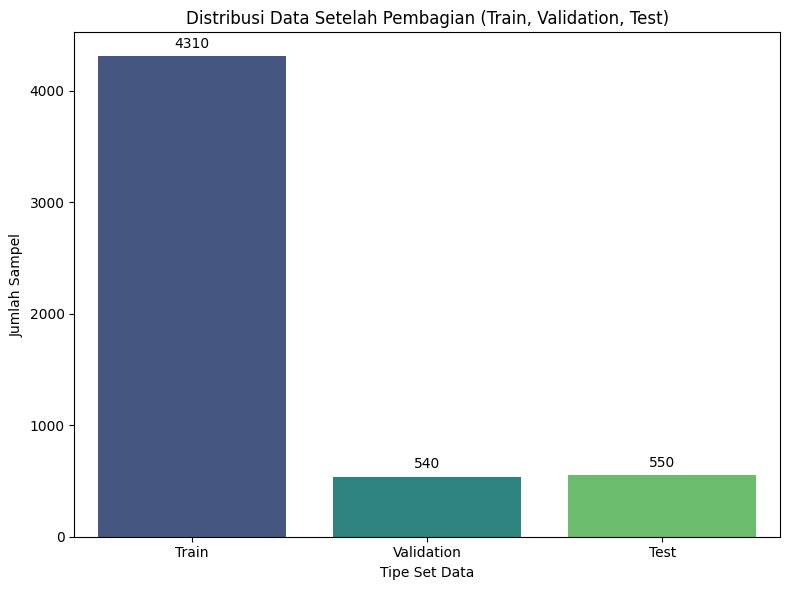


--- Distribusi aspect_label di Train set (Persentase) ---
aspect_label
0    66.24
1    33.76
Name: proportion, dtype: float64

--- Distribusi aspect_label di Validation set (Persentase) ---
aspect_label
0    67.41
1    32.59
Name: proportion, dtype: float64

--- Distribusi aspect_label di Test set (Persentase) ---
aspect_label
0    69.09
1    30.91
Name: proportion, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data ukuran set dari output sebelumnya
data_split_sizes = {
    'Train': len(train_df),
    'Validation': len(val_df),
    'Test': len(test_df)
}

# Buat DataFrame untuk visualisasi
df_split = pd.DataFrame(list(data_split_sizes.items()), columns=['Set', 'Jumlah Sampel'])

plt.figure(figsize=(8, 6))
ax = sns.barplot(x='Set', y='Jumlah Sampel', data=df_split, hue='Set', palette='viridis', legend=False)

plt.title('Distribusi Data Setelah Pembagian (Train, Validation, Test)')
plt.xlabel('Tipe Set Data')
plt.ylabel('Jumlah Sampel')

# Tambahkan label nilai di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.tight_layout()
plt.show()

print("\n--- Distribusi aspect_label di Train set (Persentase) ---")
print(train_df['aspect_label'].value_counts(normalize=True).mul(100).round(2))

print("\n--- Distribusi aspect_label di Validation set (Persentase) ---")
print(val_df['aspect_label'].value_counts(normalize=True).mul(100).round(2))

print("\n--- Distribusi aspect_label di Test set (Persentase) ---")
print(test_df['aspect_label'].value_counts(normalize=True).mul(100).round(2))

# **FINE TUNING INDOBERT**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Mendefinisikan `Dataset` PyTorch kustom bernama `ABSADataset` dan menyiapkan `DataLoader` untuk pelatihan, validasi, dan pengujian. Ini menangani tokenisasi teks dan pasangan aspek menggunakan tokenizer IndoBERT yang telah dilatih sebelumnya, menyiapkan label aspek dan sentimen, serta memformat data menjadi _batch_ yang cocok untuk masukan ke model _deep learning_ untuk _Aspect-Based Sentiment Analysis_ (ABSA).

In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

# Muat tokenizer dari direktori
tokenizer = AutoTokenizer.from_pretrained('/content/drive/MyDrive/Model_NLP/IndoBERT_Base_P1')

class ABSADataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.dataframe = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        text = str(row['text'])
        aspect = str(row['aspect'])
        aspect_label = float(row['aspect_label'])
        sentiment_label = int(row['sentiment_label'])

        # Untuk sentiment_label: -1, 0, 1, 2. Jika -1, ubah menjadi 0, 1, 2, 3 untuk CrossEntropyLoss.
        # Atau bisa juga dengan ignore_index jika -1 adalah padding.
        # Berdasarkan spesifikasi, sentiment_label adalah 0, 1, 2 untuk klasifikasi 3 kelas.
        # Asumsi -1 adalah nilai yang perlu diabaikan oleh CrossEntropyLoss.
        if sentiment_label == -1:
            # CrossEntropyLoss dengan ignore_index akan mengabaikan label ini.
            # Tetapi untuk output 3 kelas (0,1,2), kita perlu memetakan kembali jika ada label -1
            # Jika -1 berarti 'no sentiment' atau 'irrelevant', maka itu harus ditangani secara khusus.
            # Untuk saat ini, kita ikuti instruksi 'output 3 (untuk klasifikasi kelas 0, 1, 2)'.
            # Jadi, kita harus memastikan label yang masuk ke CE adalah 0, 1, 2.
            # Jika -1 adalah label valid untuk 3 kelas, perlu klarifikasi lebih lanjut.
            # Mengikuti instruksi 'ignore_index=-1', kita akan tetap menggunakan -1 untuk label yang akan diabaikan.
            sentiment_target = torch.tensor(-1, dtype=torch.long) # Akan diabaikan oleh CrossEntropyLoss
        else:
            sentiment_target = torch.tensor(sentiment_label, dtype=torch.long)

        # Tokenisasi berpasangan (text dan aspect)
        encoding = self.tokenizer(
            text,                  # Review text
            aspect,                # Aspect term
            add_special_tokens=True, # Add '[CLS]' and '[SEP]'
            max_length=self.max_length,      # Batasi panjang ke 128
            padding='max_length',  # Pad semua ke max_length
            truncation=True,       # Potong jika lebih panjang dari max_length
            return_tensors='pt'    # Kembalikan PyTorch tensors
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'aspect_label': torch.tensor(aspect_label, dtype=torch.float32),
            'sentiment_label': sentiment_target
        }

# Inisialisasi Dataset
train_dataset = ABSADataset(train_df, tokenizer)
val_dataset = ABSADataset(val_df, tokenizer)
test_dataset = ABSADataset(test_df, tokenizer)

# Inisialisasi DataLoader
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\nJumlah batch di Train Dataloader: {len(train_dataloader)}")
print(f"Jumlah batch di Validation Dataloader: {len(val_dataloader)}")
print(f"Jumlah batch di Test Dataloader: {len(test_dataloader)}")

# Contoh mengambil satu batch
print("\n--- Contoh satu batch dari Train Dataloader ---")
for batch in train_dataloader:
    print(f"Input IDs shape: {batch['input_ids'].shape}")
    print(f"Attention Mask shape: {batch['attention_mask'].shape}")
    print(f"Aspect Label shape: {batch['aspect_label'].shape}")
    print(f"Sentiment Label shape: {batch['sentiment_label'].shape}")
    break


Jumlah batch di Train Dataloader: 135
Jumlah batch di Validation Dataloader: 17
Jumlah batch di Test Dataloader: 18

--- Contoh satu batch dari Train Dataloader ---
Input IDs shape: torch.Size([32, 128])
Attention Mask shape: torch.Size([32, 128])
Aspect Label shape: torch.Size([32])
Sentiment Label shape: torch.Size([32])


Mendefinisikan arsitektur model `MultiHeadIndoBERT` menggunakan PyTorch. Model ini dibangun di atas model dasar IndoBERT yang sudah dilatih sebelumnya (`AutoModel` dari Hugging Face Transformers) dan memiliki dua kepala (`head`) terpisah: satu untuk deteksi aspek (klasifikasi biner) dan satu lagi untuk klasifikasi sentimen (klasifikasi multi-kelas). Model ini dirancang untuk tugas _Aspect-Based Sentiment Analysis_, di mana ia secara bersamaan memprediksi apakah suatu aspek disebutkan dan sentimen dari aspek tersebut jika ada.

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoModel

class MultiHeadIndoBERT(nn.Module):
    def __init__(self, base_model_path, num_sentiment_labels=3):
        super(MultiHeadIndoBERT, self).__init__()
        # Inisialisasi model dasar menggunakan AutoModel
        self.bert = AutoModel.from_pretrained(base_model_path)
        self.dropout = nn.Dropout(0.1)

        # Head Klasifikasi untuk Deteksi Aspek (Binary Classification)
        # Input 768 (output dari [CLS] token), Output 1 (untuk BCEWithLogitsLoss)
        self.aspect_head = nn.Linear(self.bert.config.hidden_size, 1)

        # Head Klasifikasi untuk Sentimen (Multi-class Classification)
        # Input 768, Output num_sentiment_labels (untuk CrossEntropyLoss)
        self.sentiment_head = nn.Linear(self.bert.config.hidden_size, num_sentiment_labels)

    def forward(self, input_ids, attention_mask):
        # Dapatkan output dari model dasar (IndoBERT)
        # output.last_hidden_state: (batch_size, sequence_length, hidden_size)
        # output.pooler_output: (batch_size, hidden_size) - ini adalah representasi [CLS] token yang sudah diproses oleh pooler
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)

        # Ekstrak representasi [CLS] token dari output (pooler_output)
        cls_embedding = output.pooler_output # Menggunakan pooler_output karena biasanya sudah diproses dengan tanh

        # Aplikasi Dropout
        cls_embedding = self.dropout(cls_embedding)

        # Loloskan embedding [CLS] ke masing-masing head
        pred_aspect = self.aspect_head(cls_embedding)
        pred_sentiment = self.sentiment_head(cls_embedding)

        return pred_aspect, pred_sentiment

# Inisialisasi model
# Pastikan path model sesuai dengan lokasi di Google Drive
model = MultiHeadIndoBERT(base_model_path='/content/drive/MyDrive/Model_NLP/IndoBERT_Base_P1', num_sentiment_labels=3)

# Pindahkan model ke CUDA jika tersedia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

print(f"Model berhasil diinisialisasi dan dipindahkan ke: {device}")
print(model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model berhasil diinisialisasi dan dipindahkan ke: cuda
MultiHeadIndoBERT(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
            

Blok kode ini mengelola siklus _fine-tuning_ model `MultiHeadIndoBERT` untuk tugas ABSA. Ini mencakup konfigurasi _hyperparameter_, _optimizer_ (`AdamW`), penjadwal _learning rate_ (`get_linear_schedule_with_warmup`), serta fungsi _loss_ (`BCEWithLogitsLoss` untuk aspek dan `CrossEntropyLoss` dengan pembobotan kelas untuk sentimen). Selain itu, kode ini mendefinisikan fungsi `train_epoch` dan `evaluate` untuk iterasi pelatihan dan evaluasi metrik kinerja (akurasi, _precision_, _recall_, F1-score) pada deteksi aspek dan klasifikasi sentimen, serta mengimplementasikan _early stopping_ untuk menyimpan model terbaik.

In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import copy
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm.notebook import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ==========================================
# 1. KONFIGURASI EKSPERIMEN (DIOPTIMALKAN)
# ==========================================
learning_rates = [1e-5, 2e-5, 3e-5, 5e-5]
fixed_max_epoch = 10
patience = 1
base_model_path = '/content/drive/MyDrive/Model_NLP/IndoBERT_Base_P1'

experiment_results = []
best_overall_f1 = -1
best_overall_history = []
best_overall_model_state = None

# Global setup
sentiment_loss_weight = 0.4
aspect_threshold = 0.5

# Kalkulasi Class Weights (Tetap sama)
valid_sentiment_df = train_df[train_df['sentiment_label'] != -1]
sentiment_label_counts = valid_sentiment_df['sentiment_label'].value_counts().sort_index()
sentiment_class_counts = {i: sentiment_label_counts.get(i, 0) for i in range(3)}
total_valid_sentiment = sum(sentiment_class_counts.values())

class_weights_list = []
for i in range(3):
    count = sentiment_class_counts[i]
    raw_weight = total_valid_sentiment / (3 * (count + 1e-5))
    class_weights_list.append(torch.sqrt(torch.tensor(raw_weight, dtype=torch.float32)))

current_class_weights = torch.stack(class_weights_list).to(device)

criterion_aspect = nn.BCEWithLogitsLoss()
criterion_sentiment = nn.CrossEntropyLoss(weight=current_class_weights)

# ==========================================
# 2. FUNGSI EVALUASI
# ==========================================
def evaluate_local(target_model, loader):
    target_model.eval()
    total_loss = 0
    all_aspect_labels, all_aspect_preds = [], []
    all_sentiment_labels, all_sentiment_preds = [], []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            aspect_labels = batch['aspect_label'].float().to(device)
            sentiment_labels = batch['sentiment_label'].long().to(device)

            pred_aspect, pred_sentiment = target_model(input_ids, attention_mask)

            loss_aspect = criterion_aspect(pred_aspect.squeeze(-1), aspect_labels)
            valid_mask = sentiment_labels != -1
            loss_sentiment = criterion_sentiment(pred_sentiment[valid_mask], sentiment_labels[valid_mask]) if valid_mask.any() else torch.tensor(0.0, device=device)

            total_loss += (loss_aspect + sentiment_loss_weight * loss_sentiment).item()

            preds_aspect = (torch.sigmoid(pred_aspect).squeeze(-1) >= aspect_threshold).int()
            all_aspect_labels.extend(aspect_labels.cpu().numpy())
            all_aspect_preds.extend(preds_aspect.cpu().numpy())

            if valid_mask.any():
                all_sentiment_labels.extend(sentiment_labels[valid_mask].cpu().numpy())
                all_sentiment_preds.extend(torch.argmax(pred_sentiment[valid_mask], dim=1).cpu().numpy())

    aspect_f1 = precision_recall_fscore_support(all_aspect_labels, all_aspect_preds, average='binary', zero_division=0)[2]
    sentiment_f1 = precision_recall_fscore_support(all_sentiment_labels, all_sentiment_preds, average='macro', zero_division=0)[2]

    return {
        'loss': total_loss / len(loader),
        'aspect_acc': accuracy_score(all_aspect_labels, all_aspect_preds),
        'aspect_f1': aspect_f1,
        'sentiment_acc': accuracy_score(all_sentiment_labels, all_sentiment_preds),
        'sentiment_f1': sentiment_f1
    }

# ==========================================
# 3. FUNGSI EKSPERIMEN (VISUALISASI REAL-TIME)
# ==========================================
def run_experiment(lr, total_epochs):
    exp_model = MultiHeadIndoBERT(base_model_path=base_model_path, num_sentiment_labels=3).to(device)
    optimizer = AdamW(exp_model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_dataloader) * total_epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps)

    best_val_loss = float('inf')
    best_exp_metrics = {}
    exp_history = []
    patience_counter = 0
    stopped_epoch = total_epochs

    print(f"\n{'='*50}\n>>> MEMULAI EKSPERIMEN: LR={lr} | Max Epoch={total_epochs}\n{'='*50}")

    for epoch in range(total_epochs):
        exp_model.train()
        train_loss = 0
        for batch in train_dataloader:
            input_ids, attention_mask = batch['input_ids'].to(device), batch['attention_mask'].to(device)
            aspect_labels, sentiment_labels = batch['aspect_label'].to(device), batch['sentiment_label'].to(device)

            optimizer.zero_grad()
            p_asp, p_sent = exp_model(input_ids, attention_mask)
            l_asp = criterion_aspect(p_asp.squeeze(-1), aspect_labels.float())
            v_mask = sentiment_labels != -1
            l_sent = criterion_sentiment(p_sent[v_mask], sentiment_labels[v_mask]) if v_mask.any() else torch.tensor(0.0, device=device, requires_grad=True)
            loss = l_asp + sentiment_loss_weight * l_sent
            loss.backward()
            optimizer.step()
            scheduler.step()
            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_dataloader)
        val_result = evaluate_local(exp_model, val_dataloader)

        # Visualisasi Pemrosesan Per Epoch
        print(f"  Epoch {epoch + 1:02d}/{total_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_result['loss']:.4f} | Sentiment Mac-F1: {val_result['sentiment_f1']:.4f} | Aspect F1: {val_result['aspect_f1']:.4f}")

        exp_history.append({'epoch': epoch + 1, 'train_loss': avg_train_loss, 'val_loss': val_result['loss'], 'aspect_acc': val_result['aspect_acc'], 'aspect_f1': val_result['aspect_f1'], 'sentiment_acc': val_result['sentiment_acc'], 'sentiment_f1': val_result['sentiment_f1']})

        # Ekstraksi Matriks Lengkap saat Validation Loss Terbaik Ditemukan
        if val_result['loss'] < best_val_loss:
            best_val_loss = val_result['loss']
            best_exp_metrics = {
                **val_result,
                'train_loss': avg_train_loss,  # EKSTRAKSI MUTLAK KE MEMORI
                'val_loss': val_result['loss'],
                'sentiment_macro_f1': val_result['sentiment_f1'],
                'aspect_accuracy': val_result['aspect_acc'],
                'sentiment_accuracy': val_result['sentiment_acc'],
                'state_dict': copy.deepcopy(exp_model.state_dict()),
                'history': exp_history
            }
            patience_counter = 0
            print(f"      -> [Model Disimpan] Val Loss turun ke {best_val_loss:.4f}")
        else:
            patience_counter += 1
            print(f"      -> Patience: {patience_counter}/{patience}")

        if patience_counter >= patience:
            stopped_epoch = epoch + 1
            print(f"\n  [INFO] Early Stopping dipicu pada epoch {stopped_epoch}.")
            break

    return lr, stopped_epoch, best_exp_metrics

# ==========================================
# 4. EKSEKUSI ITERASI LINIER (HANYA 4 KALI)
# ==========================================
for lr in learning_rates:
    curr_lr, stop_ep, res = run_experiment(lr, fixed_max_epoch)

    # Agregasi ke Struktur Data Tabel Akhir
    experiment_results.append({
        'learning_rate': curr_lr,
        'max_epoch_limit': fixed_max_epoch,
        'stopped_epoch': stop_ep,
        'train_loss': res.get('train_loss', None),
        'val_loss': res.get('val_loss', None),
        'aspect_accuracy': res['aspect_accuracy'],
        'aspect_f1': res['aspect_f1'],
        'sentiment_accuracy': res['sentiment_accuracy'],
        'sentiment_macro_f1': res['sentiment_macro_f1']
    })

    if res['sentiment_macro_f1'] > best_overall_f1:
        best_overall_f1 = res['sentiment_macro_f1']
        best_overall_history = res['history']
        best_overall_model_state = res['state_dict']

# ==========================================
# 5. RENDER TABEL HASIL AKHIR
# ==========================================
print("\n" + "="*50)
print(">>> REKAPITULASI HASIL EKSPERIMEN HYPERPARAMETER")
print("="*50)

results_df = pd.DataFrame(experiment_results).sort_values(by=['sentiment_macro_f1', 'val_loss'], ascending=[False, True])
results_df.to_csv('hyperparameter_experiment_results.csv', index=False)
display(results_df)

if best_overall_model_state:
    model.load_state_dict(best_overall_model_state) # Asumsi model diinstansiasi secara global
    history = best_overall_history
    print(f"\n[SISTEM] Bobot model dikembalikan ke performa terbaik (Sentiment Macro F1: {best_overall_f1:.4f})")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


>>> MEMULAI EKSPERIMEN: LR=1e-05 | Max Epoch=10
  Epoch 01/10 | Train Loss: 0.8822 | Val Loss: 0.5347 | Sentiment Mac-F1: 0.4950 | Aspect F1: 0.8802
      -> [Model Disimpan] Val Loss turun ke 0.5347
  Epoch 02/10 | Train Loss: 0.4825 | Val Loss: 0.3827 | Sentiment Mac-F1: 0.6668 | Aspect F1: 0.9112
      -> [Model Disimpan] Val Loss turun ke 0.3827
  Epoch 03/10 | Train Loss: 0.3117 | Val Loss: 0.3330 | Sentiment Mac-F1: 0.7378 | Aspect F1: 0.9143
      -> [Model Disimpan] Val Loss turun ke 0.3330
  Epoch 04/10 | Train Loss: 0.2312 | Val Loss: 0.3136 | Sentiment Mac-F1: 0.7848 | Aspect F1: 0.9235
      -> [Model Disimpan] Val Loss turun ke 0.3136
  Epoch 05/10 | Train Loss: 0.1707 | Val Loss: 0.3085 | Sentiment Mac-F1: 0.7975 | Aspect F1: 0.9385
      -> [Model Disimpan] Val Loss turun ke 0.3085
  Epoch 06/10 | Train Loss: 0.1263 | Val Loss: 0.3370 | Sentiment Mac-F1: 0.8095 | Aspect F1: 0.9274
      -> Patience: 1/1

  [INFO] Early Stopping dipicu pada epoch 6.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


>>> MEMULAI EKSPERIMEN: LR=2e-05 | Max Epoch=10
  Epoch 01/10 | Train Loss: 0.8205 | Val Loss: 0.5196 | Sentiment Mac-F1: 0.5546 | Aspect F1: 0.8943
      -> [Model Disimpan] Val Loss turun ke 0.5196
  Epoch 02/10 | Train Loss: 0.4204 | Val Loss: 0.3425 | Sentiment Mac-F1: 0.7358 | Aspect F1: 0.9292
      -> [Model Disimpan] Val Loss turun ke 0.3425
  Epoch 03/10 | Train Loss: 0.2753 | Val Loss: 0.2979 | Sentiment Mac-F1: 0.7653 | Aspect F1: 0.9356
      -> [Model Disimpan] Val Loss turun ke 0.2979
  Epoch 04/10 | Train Loss: 0.1832 | Val Loss: 0.3052 | Sentiment Mac-F1: 0.7620 | Aspect F1: 0.9333
      -> Patience: 1/1

  [INFO] Early Stopping dipicu pada epoch 4.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


>>> MEMULAI EKSPERIMEN: LR=3e-05 | Max Epoch=10
  Epoch 01/10 | Train Loss: 0.7761 | Val Loss: 0.4963 | Sentiment Mac-F1: 0.5429 | Aspect F1: 0.8953
      -> [Model Disimpan] Val Loss turun ke 0.4963
  Epoch 02/10 | Train Loss: 0.4258 | Val Loss: 0.3534 | Sentiment Mac-F1: 0.7353 | Aspect F1: 0.9133
      -> [Model Disimpan] Val Loss turun ke 0.3534
  Epoch 03/10 | Train Loss: 0.2629 | Val Loss: 0.3297 | Sentiment Mac-F1: 0.7715 | Aspect F1: 0.9315
      -> [Model Disimpan] Val Loss turun ke 0.3297
  Epoch 04/10 | Train Loss: 0.1544 | Val Loss: 0.3281 | Sentiment Mac-F1: 0.7901 | Aspect F1: 0.9274
      -> [Model Disimpan] Val Loss turun ke 0.3281
  Epoch 05/10 | Train Loss: 0.1082 | Val Loss: 0.3317 | Sentiment Mac-F1: 0.7806 | Aspect F1: 0.9330
      -> Patience: 1/1

  [INFO] Early Stopping dipicu pada epoch 5.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


>>> MEMULAI EKSPERIMEN: LR=5e-05 | Max Epoch=10
  Epoch 01/10 | Train Loss: 0.7326 | Val Loss: 0.4184 | Sentiment Mac-F1: 0.6235 | Aspect F1: 0.9117
      -> [Model Disimpan] Val Loss turun ke 0.4184
  Epoch 02/10 | Train Loss: 0.3932 | Val Loss: 0.3065 | Sentiment Mac-F1: 0.7663 | Aspect F1: 0.9379
      -> [Model Disimpan] Val Loss turun ke 0.3065
  Epoch 03/10 | Train Loss: 0.2477 | Val Loss: 0.3549 | Sentiment Mac-F1: 0.7676 | Aspect F1: 0.9071
      -> Patience: 1/1

  [INFO] Early Stopping dipicu pada epoch 3.

>>> REKAPITULASI HASIL EKSPERIMEN HYPERPARAMETER


,learning_rate,max_epoch_limit,stopped_epoch,train_loss,val_loss,aspect_accuracy,aspect_f1,sentiment_accuracy,sentiment_macro_f1
0,0.00001,10,6,0.170662,0.308459,0.959259,0.938547,0.892045,0.797479
2,0.00003,10,5,0.154407,0.328146,0.951852,0.927374,0.880682,0.790064
3,0.00005,10,3,0.393165,0.306476,0.959259,0.937853,0.875000,0.766273
1,0.00002,10,4,0.275261,0.297865,0.957407,0.935574,0.880682,0.765337



[SISTEM] Bobot model dikembalikan ke performa terbaik (Sentiment Macro F1: 0.7975)



>>> VISUALISASI PERBANDINGAN HASIL EKSPERIMEN


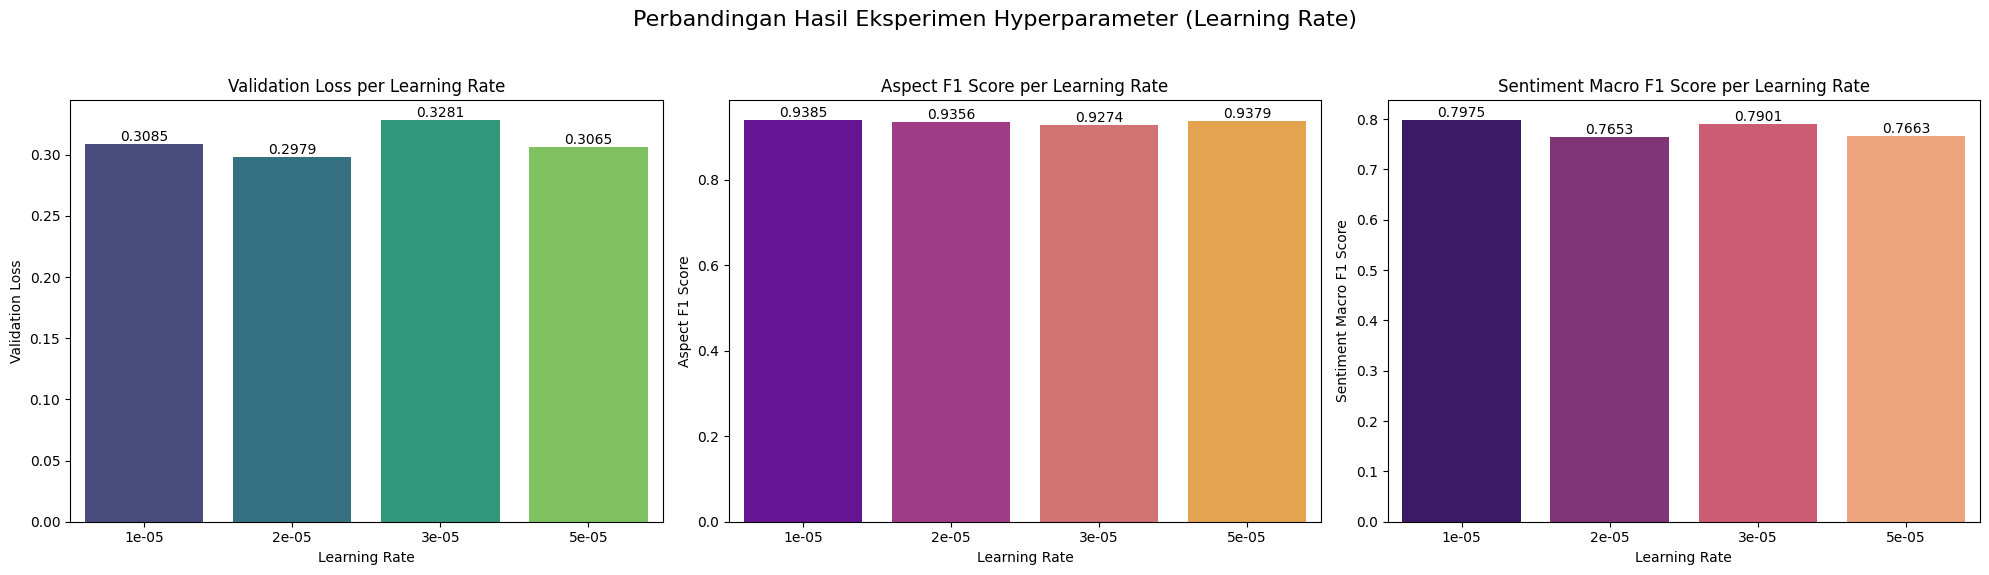

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan results_df sudah ada dari eksekusi sel sebelumnya
if 'results_df' not in locals():
    print("Error: 'results_df' not found. Please run the hyperparameter experiment cell first.")
else:
    print("\n==================================================")
    print(">>> VISUALISASI PERBANDINGAN HASIL EKSPERIMEN")
    print("==================================================")

    # Sort by learning rate for better visualization order
    results_df_sorted = results_df.sort_values(by='learning_rate').reset_index(drop=True)

    # Konversi learning_rate ke string untuk label x-axis
    results_df_sorted['learning_rate_str'] = results_df_sorted['learning_rate'].astype(str)

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle('Perbandingan Hasil Eksperimen Hyperparameter (Learning Rate)', fontsize=16)

    # Plot Validation Loss
    sns.barplot(x='learning_rate_str', y='val_loss', data=results_df_sorted, ax=axes[0], palette='viridis', hue='learning_rate_str', legend=False)
    axes[0].set_title('Validation Loss per Learning Rate')
    axes[0].set_xlabel('Learning Rate')
    axes[0].set_ylabel('Validation Loss')
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt='%.4f')

    # Plot Aspect F1 Score
    sns.barplot(x='learning_rate_str', y='aspect_f1', data=results_df_sorted, ax=axes[1], palette='plasma', hue='learning_rate_str', legend=False)
    axes[1].set_title('Aspect F1 Score per Learning Rate')
    axes[1].set_xlabel('Learning Rate')
    axes[1].set_ylabel('Aspect F1 Score')
    for container in axes[1].containers:
        axes[1].bar_label(container, fmt='%.4f')

    # Plot Sentiment Macro F1 Score
    sns.barplot(x='learning_rate_str', y='sentiment_macro_f1', data=results_df_sorted, ax=axes[2], palette='magma', hue='learning_rate_str', legend=False)
    axes[2].set_title('Sentiment Macro F1 Score per Learning Rate')
    axes[2].set_xlabel('Learning Rate')
    axes[2].set_ylabel('Sentiment Macro F1 Score')
    for container in axes[2].containers:
        axes[2].bar_label(container, fmt='%.4f')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
    plt.show()

In [ ]:
best_experiment_row = results_df.iloc[0]

# Tampilkan skenario model terbaik
print("==================================================")
print(">>> RINGKASAN SKENARIO MODEL TERBAIK")
print("==================================================")
print(f"Learning Rate Terbaik: {best_experiment_row['learning_rate']}")
print(f"Validation Loss Terbaik: {best_experiment_row['val_loss']:.4f}")
print(f"Aspect F1 Score Terbaik: {best_experiment_row['aspect_f1']:.4f}")
print(f"Sentiment Macro F1 Score Terbaik: {best_experiment_row['sentiment_macro_f1']:.4f}")
print(f"Epoch saat bobot terbaik disimpan (berdasarkan validasi loss): {best_experiment_row['stopped_epoch'] - patience:.0f}")
print(f"Epoch terakhir training: {best_experiment_row['stopped_epoch']:.0f}")


print("\n==================================================")
print(">>> PERFORMA MODEL TERBAIK PER EPOCH")
print("==================================================")
# Iterasi melalui riwayat pelatihan model terbaik
# 'history' sudah menyimpan riwayat dari model terbaik secara global
for entry in best_overall_history:
    print(f"Epoch {entry['epoch']:02d}: "
          f"Train Loss={entry['train_loss']:.4f}, "
          f"Val Loss={entry['val_loss']:.4f}, "
          f"Aspect Acc={entry['aspect_acc']:.4f}, "
          f"Aspect F1={entry['aspect_f1']:.4f}, "
          f"Sentiment Acc={entry['sentiment_acc']:.4f}, "
          f"Sentiment F1={entry['sentiment_f1']:.4f}")

>>> RINGKASAN SKENARIO MODEL TERBAIK
Learning Rate Terbaik: 1e-05
Validation Loss Terbaik: 0.3085
Aspect F1 Score Terbaik: 0.9385
Sentiment Macro F1 Score Terbaik: 0.7975
Epoch saat bobot terbaik disimpan (berdasarkan validasi loss): 5
Epoch terakhir training: 6

>>> PERFORMA MODEL TERBAIK PER EPOCH
Epoch 01: Train Loss=0.8822, Val Loss=0.5347, Aspect Acc=0.9204, Aspect F1=0.8802, Sentiment Acc=0.7727, Sentiment F1=0.4950
Epoch 02: Train Loss=0.4825, Val Loss=0.3827, Aspect Acc=0.9426, Aspect F1=0.9112, Sentiment Acc=0.8182, Sentiment F1=0.6668
Epoch 03: Train Loss=0.3117, Val Loss=0.3330, Aspect Acc=0.9444, Aspect F1=0.9143, Sentiment Acc=0.8580, Sentiment F1=0.7378
Epoch 04: Train Loss=0.2312, Val Loss=0.3136, Aspect Acc=0.9481, Aspect F1=0.9235, Sentiment Acc=0.8807, Sentiment F1=0.7848
Epoch 05: Train Loss=0.1707, Val Loss=0.3085, Aspect Acc=0.9593, Aspect F1=0.9385, Sentiment Acc=0.8920, Sentiment F1=0.7975
Epoch 06: Train Loss=0.1263, Val Loss=0.3370, Aspect Acc=0.9519, Aspect F1

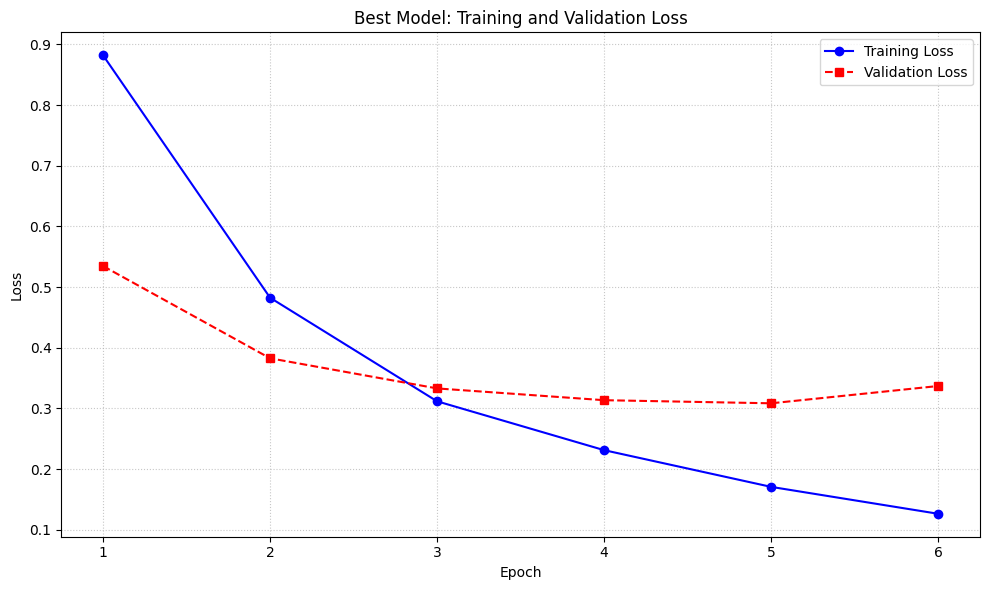

In [ ]:
import matplotlib.pyplot as plt

# Using 'history' which was updated with the best experiment results
epochs_range = [h['epoch'] for h in history]
train_losses = [h['train_loss'] for h in history]
val_losses = [h['val_loss'] for h in history]

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, train_losses, label='Training Loss', marker='o', linestyle='-', color='b')
plt.plot(epochs_range, val_losses, label='Validation Loss', marker='s', linestyle='--', color='r')

plt.title('Best Model: Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(epochs_range)
plt.tight_layout()
plt.show()

Memvisualisasikan proses pelatihan model dengan menampilkan grafik training loss dan validation loss, serta grafik performa Aspect Detection dan Sentiment Classification berdasarkan metrik Accuracy dan Macro F1 Score pada setiap epoch.

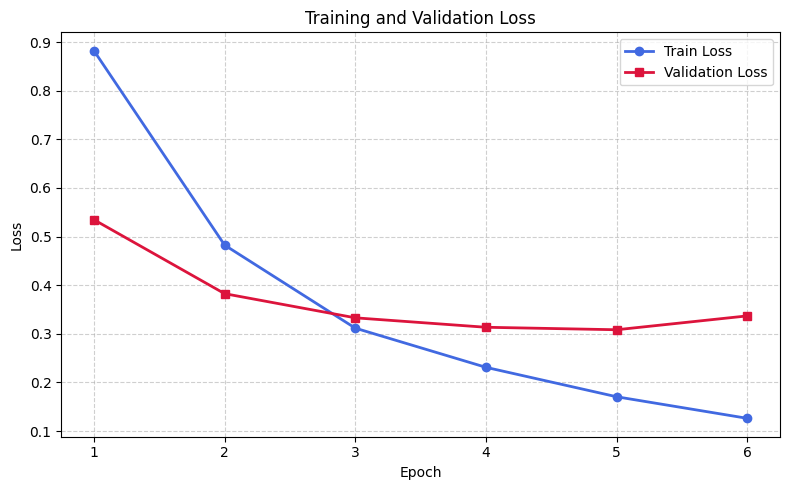

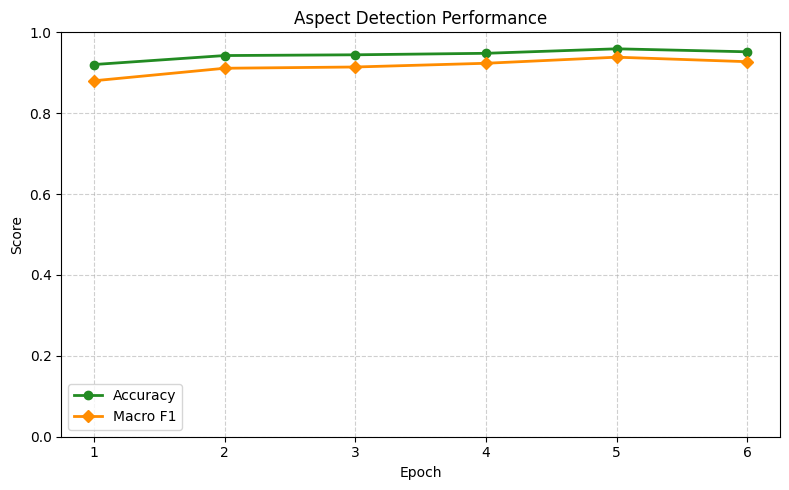

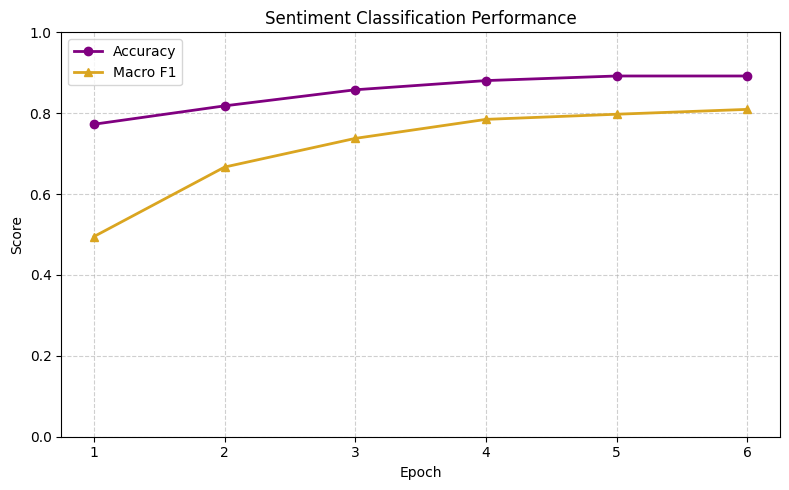

In [ ]:
# @title
import matplotlib.pyplot as plt

# Ekstrak data
epochs = [h['epoch'] for h in history]

train_losses = [h['train_loss'] for h in history]
val_losses = [h['val_loss'] for h in history]

aspect_acc = [h['aspect_acc'] for h in history]
aspect_f1 = [h['aspect_f1'] for h in history]

sentiment_acc = [h['sentiment_acc'] for h in history]
sentiment_f1 = [h['sentiment_f1'] for h in history]

# Plot Loss
plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    train_losses,
    marker='o',
    linewidth=2,
    color='royalblue',
    label='Train Loss'
)

plt.plot(
    epochs,
    val_losses,
    marker='s',
    linewidth=2,
    color='crimson',
    label='Validation Loss'
)

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Plot Aspect Detection
plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    aspect_acc,
    marker='o',
    linewidth=2,
    color='forestgreen',
    label='Accuracy'
)

plt.plot(
    epochs,
    aspect_f1,
    marker='D',
    linewidth=2,
    color='darkorange',
    label='Macro F1'
)

plt.title('Aspect Detection Performance')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Plot Sentiment Classification
plt.figure(figsize=(8,5))

plt.plot(
    epochs,
    sentiment_acc,
    marker='o',
    linewidth=2,
    color='purple',
    label='Accuracy'
)

plt.plot(
    epochs,
    sentiment_f1,
    marker='^',
    linewidth=2,
    color='goldenrod',
    label='Macro F1'
)

plt.title('Sentiment Classification Performance')
plt.xlabel('Epoch')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# **EVALUASI MODEL**

Menampilkan confusion matrix untuk mengevaluasi kinerja model pada tugas Aspect Detection dengan membandingkan label aktual dan hasil prediksi pada data pengujian. Visualisasi ini membantu mengidentifikasi jumlah prediksi benar maupun kesalahan klasifikasi pada kelas Aspect Present dan No Aspect.

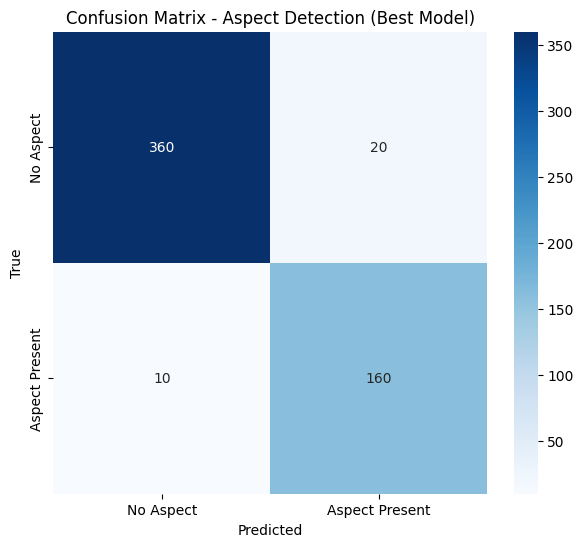

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Mengambil label aktual dan prediksi dari test_result
aspect_labels = np.array(test_result['all_aspect_labels']).astype(int)
aspect_preds = np.array(test_result['all_aspect_preds']).astype(int)

# Membuat Confusion Matrix
cm_aspect = confusion_matrix(aspect_labels, aspect_preds)
aspect_names = ['No Aspect', 'Aspect Present']

# Visualisasi Heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(cm_aspect, annot=True, fmt='d', cmap='Blues',
            xticklabels=aspect_names, yticklabels=aspect_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - Aspect Detection (Best Model)')
plt.show()

Menampilkan confusion matrix untuk mengevaluasi kinerja model pada tugas Sentiment Classification dengan membandingkan label sentimen aktual dan hasil prediksi pada data pengujian. Visualisasi ini menunjukkan distribusi prediksi benar dan kesalahan klasifikasi pada kelas Negative, Neutral, dan Positive.

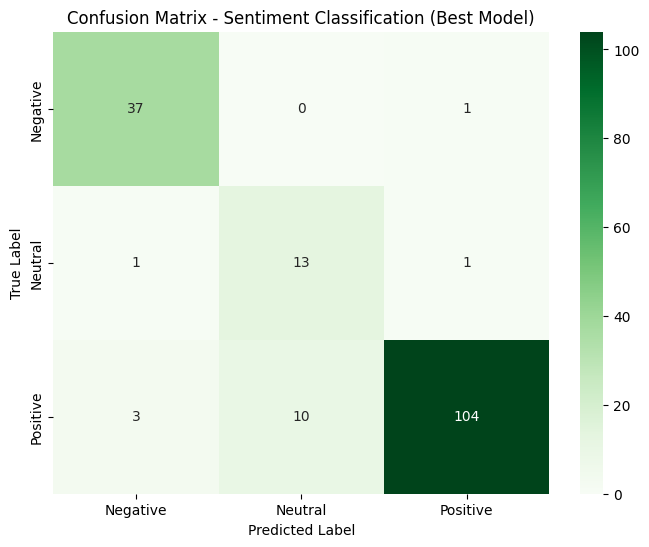

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Mengambil label aktual dan prediksi dari test_result
sent_labels = test_result['all_sentiment_labels']
sent_preds = test_result['all_sentiment_preds']
sentiment_names = ['Negative', 'Neutral', 'Positive']

if len(sent_labels) > 0:
    # Membuat Confusion Matrix
    cm_sent = confusion_matrix(sent_labels, sent_preds)

    # Visualisasi Heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_sent, annot=True, fmt='d', cmap='Greens',
                xticklabels=sentiment_names, yticklabels=sentiment_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix - Sentiment Classification (Best Model)')
    plt.show()
else:
    print('Tidak ada sampel sentimen valid yang ditemukan.')

Melakukan evaluasi model pada data pengujian dengan menghitung nilai loss, accuracy, precision, recall, dan F1-score untuk tugas Aspect Detection dan Sentiment Classification, serta menghasilkan classification report untuk analisis performa yang lebih rinci.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

import numpy as np

# EVALUATION FUNCTION
def evaluate(data_loader):

    model.eval()
    total_loss = 0
    all_aspect_labels = []
    all_aspect_preds = []
    all_sentiment_labels = []
    all_sentiment_preds = []

    with torch.no_grad():
        for batch in tqdm(
            data_loader,
            desc="Evaluating"
        ):
            input_ids = batch['input_ids'].to(device)
            attention_mask = (
                batch['attention_mask']
                .to(device)
            )

            aspect_labels = (
                batch['aspect_label']
                .float()
                .to(device)
            )

            sentiment_labels = (
                batch['sentiment_label']
                .long()
                .to(device)
            )

            # FORWARD
            pred_aspect, pred_sentiment = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # ASPECT LOSS
            loss_aspect = criterion_aspect(
                pred_aspect.squeeze(-1),
                aspect_labels
            )

            # SENTIMENT LOSS
            valid_mask = sentiment_labels != -1

            if valid_mask.sum().item() > 0:

                valid_pred_sentiment = (
                    pred_sentiment[valid_mask]
                )

                valid_sentiment_labels = (
                    sentiment_labels[valid_mask]
                )

                loss_sentiment = criterion_sentiment(
                    valid_pred_sentiment,
                    valid_sentiment_labels
                )

            else:
                loss_sentiment = torch.tensor(
                    0.0,
                    device=device
                )

            # TOTAL LOSS
            loss = (
                loss_aspect
                + sentiment_loss_weight * loss_sentiment
            )
            total_loss += loss.item()

            # ASPECT PREDICTION
            probs_aspect = torch.sigmoid(
                pred_aspect
            ).squeeze(-1)

            preds_aspect = (
                probs_aspect >= aspect_threshold
            ).int()

            all_aspect_labels.extend(
                aspect_labels.cpu().numpy()
            )

            all_aspect_preds.extend(
                preds_aspect.cpu().numpy()
            )

            # SENTIMENT PREDICTION
            if valid_mask.sum().item() > 0:

                sentiment_preds = torch.argmax(
                    valid_pred_sentiment,
                    dim=1
                )

                all_sentiment_labels.extend(
                    valid_sentiment_labels
                    .cpu()
                    .numpy()
                )

                all_sentiment_preds.extend(
                    sentiment_preds
                    .cpu()
                    .numpy()
                )

    # METRIC ASPECT
    aspect_acc = accuracy_score(
        all_aspect_labels,
        all_aspect_preds
    )

    (
        aspect_precision,
        aspect_recall,
        aspect_f1,
        _
    ) = precision_recall_fscore_support(
        all_aspect_labels,
        all_aspect_preds,
        average='binary',
        zero_division=0
    )

    # METRIC SENTIMENT
    sentiment_acc = accuracy_score(
        all_sentiment_labels,
        all_sentiment_preds
    )

    (
        sentiment_precision,
        sentiment_recall,
        sentiment_f1,
        _
    ) = precision_recall_fscore_support(
        all_sentiment_labels,
        all_sentiment_preds,
        average='macro',
        zero_division=0
    )

    # RETURN
    return {
        'loss': total_loss / len(data_loader),

        # aspect metric
        'aspect_acc': aspect_acc,
        'aspect_precision': aspect_precision,
        'aspect_recall': aspect_recall,
        'aspect_f1': aspect_f1,

        # sentiment metric
        'sentiment_acc': sentiment_acc,
        'sentiment_precision': sentiment_precision,
        'sentiment_recall': sentiment_recall,
        'sentiment_f1': sentiment_f1,

        # aspect prediction
        'all_aspect_labels': all_aspect_labels,
        'all_aspect_preds': all_aspect_preds,

        # sentiment prediction
        'all_sentiment_labels': all_sentiment_labels,
        'all_sentiment_preds': all_sentiment_preds
    }

# TEST EVALUATION
test_result = evaluate(
    test_dataloader
)

print("\n==============================")
print("EVALUASI PADA TEST SET")
print("==============================")

# LOSS
print(
    f"\nTest Loss: "
    f"{test_result['loss']:.4f}"
)

# ASPECT DETECTION
print("\n==============================")
print("ASPECT DETECTION")
print("==============================")
print(
    f"Accuracy : "
    f"{test_result['aspect_acc']:.4f}"
)
print(
    f"Precision: "
    f"{test_result['aspect_precision']:.4f}"
)
print(
    f"Recall   : "
    f"{test_result['aspect_recall']:.4f}"
)
print(
    f"F1 Score : "
    f"{test_result['aspect_f1']:.4f}"
)
print("\n--- Classification Report Aspect ---")
print(
    classification_report(
        np.array(
            test_result['all_aspect_labels']
        ).astype(int),

        np.array(
            test_result['all_aspect_preds']
        ).astype(int),

        target_names=[
            'No Aspect',
            'Aspect Present'
        ],

        digits=4,
        zero_division=0
    )
)

# SENTIMENT CLASSIFICATION
print("\n==============================")
print("SENTIMENT CLASSIFICATION")
print("==============================")
print(
    f"Accuracy : "
    f"{test_result['sentiment_acc']:.4f}"
)
print(
    f"Precision: "
    f"{test_result['sentiment_precision']:.4f}"
)
print(
    f"Recall   : "
    f"{test_result['sentiment_recall']:.4f}"
)
print(
    f"Macro F1 : "
    f"{test_result['sentiment_f1']:.4f}"
)
print(
    "\n--- Classification Report "
    "Sentiment ---"
)
print(
    classification_report(
        test_result['all_sentiment_labels'],
        test_result['all_sentiment_preds'],

        target_names=[
            'Negative',
            'Neutral',
            'Positive'
        ],

        digits=4,
        zero_division=0
    )
)

Evaluating:   0%|          | 0/18 [00:00<?, ?it/s]


EVALUASI PADA TEST SET

Test Loss: 0.2343

ASPECT DETECTION
Accuracy : 0.9455
Precision: 0.8889
Recall   : 0.9412
F1 Score : 0.9143

--- Classification Report Aspect ---
                precision    recall  f1-score   support

     No Aspect     0.9730    0.9474    0.9600       380
Aspect Present     0.8889    0.9412    0.9143       170

      accuracy                         0.9455       550
     macro avg     0.9309    0.9443    0.9371       550
  weighted avg     0.9470    0.9455    0.9459       550


SENTIMENT CLASSIFICATION
Accuracy : 0.9059
Precision: 0.8163
Recall   : 0.9097
Macro F1 : 0.8512

--- Classification Report Sentiment ---
              precision    recall  f1-score   support

    Negative     0.9024    0.9737    0.9367        38
     Neutral     0.5652    0.8667    0.6842        15
    Positive     0.9811    0.8889    0.9327       117

    accuracy                         0.9059       170
   macro avg     0.8163    0.9097    0.8512       170
weighted avg     0.9268  

Melakukan analisis kesalahan (error analysis) dengan mengidentifikasi sampel yang salah diklasifikasikan pada tugas Aspect Detection dan Sentiment Classification. Hasil analisis digunakan untuk menampilkan contoh prediksi yang tidak sesuai dengan label sebenarnya sehingga dapat membantu memahami kelemahan model.

In [ ]:
# Buat DataFrame untuk analisis kesalahan
error_analysis_df = test_df.copy().reset_index(drop=True)

# Tambahkan kolom prediksi aspek dan sentimen
error_analysis_df['true_aspect_label'] = np.array(test_result['all_aspect_labels']).astype(int)
error_analysis_df['pred_aspect_label'] = np.array(test_result['all_aspect_preds']).astype(int)

# Inisialisasi kolom untuk true dan predicted sentiment dengan nilai default -1
error_analysis_df['true_sentiment_label'] = -1
error_analysis_df['pred_sentiment_label'] = -1

# Buat mask untuk mengidentifikasi baris di error_analysis_df yang memiliki label sentimen valid
valid_sentiment_mask = error_analysis_df['sentiment_label'] != -1

# Dapatkan indeks dari baris-baris yang memiliki sentimen valid
indices_with_valid_sentiment = error_analysis_df[valid_sentiment_mask].index

# Pastikan jumlah elemen yang valid di mask sama dengan panjang list hasil evaluasi sentimen
if len(indices_with_valid_sentiment) != len(test_result['all_sentiment_labels']):
    raise ValueError(
        "Length mismatch for valid sentiment labels. "
        "The number of valid sentiment rows in test_df does not match the length of collected sentiment labels." # noqa
    )

# Buat Series baru dengan data sentimen dan indeks yang sesuai
true_sentiment_series_for_assignment = pd.Series(
    test_result['all_sentiment_labels'],
    index=indices_with_valid_sentiment,
    dtype=int # Ensure dtype is integer for sentiment labels
)
pred_sentiment_series_for_assignment = pd.Series(
    test_result['all_sentiment_preds'],
    index=indices_with_valid_sentiment,
    dtype=int # Ensure dtype is integer for sentiment predictions
)

# Gunakan .loc untuk mengisi hanya baris-baris yang valid dengan data sentimen yang sudah diindeks
error_analysis_df.loc[indices_with_valid_sentiment, 'true_sentiment_label'] = true_sentiment_series_for_assignment
error_analysis_df.loc[indices_with_valid_sentiment, 'pred_sentiment_label'] = pred_sentiment_series_for_assignment

print("\n--- Sampel Misklasifikasi Deteksi Aspek ---")
# Temukan sampel di mana prediksi aspek salah
misclassified_aspect_df = error_analysis_df[error_analysis_df['true_aspect_label'] != error_analysis_df['pred_aspect_label']]

if not misclassified_aspect_df.empty:
    print(f"Ditemukan {len(misclassified_aspect_df)} sampel dengan misklasifikasi aspek:")
    display(misclassified_aspect_df[['text', 'aspect', 'true_aspect_label', 'pred_aspect_label']].head(10))
else:
    print("Tidak ada sampel yang salah diklasifikasikan untuk deteksi aspek.")

print("\n--- Sampel Misklasifikasi Klasifikasi Sentimen (hanya pada aspek yang benar) ---")
# Temukan sampel di mana aspeknya benar dan sentimennya salah (dan sentimen bukan -1)
misclassified_sentiment_df = error_analysis_df[
    (error_analysis_df['true_aspect_label'] == 1) & # Hanya fokus pada true_aspect_label = 1
    (error_analysis_df['true_sentiment_label'] != -1) & # Hanya jika ada label sentimen valid (sudah diisi)
    (error_analysis_df['true_sentiment_label'] != error_analysis_df['pred_sentiment_label'])
].copy() # Tambahkan .copy() untuk menghindari SettingWithCopyWarning

if not misclassified_sentiment_df.empty:
    print(f"Ditemukan {len(misclassified_sentiment_df)} sampel dengan misklasifikasi sentimen:")
    # Map numerical sentiment labels to descriptive names for better readability
    sentiment_label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
    misclassified_sentiment_df['true_sentiment_name'] = misclassified_sentiment_df['true_sentiment_label'].map(sentiment_label_map)
    misclassified_sentiment_df['pred_sentiment_name'] = misclassified_sentiment_df['pred_sentiment_label'].map(sentiment_label_map)
    display(misclassified_sentiment_df[['text', 'aspect', 'true_sentiment_name', 'pred_sentiment_name']].head(10))
else:
    print("Tidak ada sampel yang salah diklasifikasikan untuk sentimen (dengan aspek yang benar).")


--- Sampel Misklasifikasi Deteksi Aspek ---
Ditemukan 30 sampel dengan misklasifikasi aspek:


,text,aspect,true_aspect_label,pred_aspect_label
2,"""""""Untuk parkiran cukup luas dan aman untuk mo...",suasana,0,1
7,"""""""Tempat makan BPK dengan rasa menu lezat. Ha...",suasana,1,0
39,Salah satu rumah makan yang enak di kota Medan.,lokasi,1,0
47,Saat BPK di malam hari sudah tutup.. di sini m...,suasana,0,1
52,Parkir kurang nyaman,suasana,0,1
60,"""""""Suasananya bagus, tempat nya juga bersih, t...",makanan,0,1
70,"""""""Mantap promonya, sekali makan dapat pohon c...",makanan,0,1
75,"""""""Mantap promonya, sekali makan dapat pohon c...",makanan,0,1
87,Beli makan berhadiah 3 bibit pohon cabai hanya...,suasana,0,1
120,"""""""ya biasa saja . Standar BPK pada umumnya, l...",makanan,1,0



--- Sampel Misklasifikasi Klasifikasi Sentimen (hanya pada aspek yang benar) ---
Ditemukan 16 sampel dengan misklasifikasi sentimen:


,text,aspect,true_sentiment_name,pred_sentiment_name
4,"""""""Untuk parkiran cukup luas dan aman untuk mo...",lokasi,Positive,Negative
12,"""""""lokasi di pinggir jalan raya, Okelah tempat...",suasana,Positive,Neutral
45,Saat BPK di malam hari sudah tutup.. di sini m...,makanan,Positive,Negative
105,"""""""Terbaiklah pokoknya,soal rasa boleh diadu h...",makanan,Positive,Neutral
150,"""""""Tempat makan BPK terkenal di kota Medan, lo...",makanan,Positive,Neutral
236,"""""""datang sore hari tidak terlalu penuh. Pesan...",pelayanan,Positive,Negative
237,"""""""datang sore hari tidak terlalu penuh. Pesan...",suasana,Positive,Neutral
245,Daging merahnya paling oke,makanan,Negative,Positive
276,"""""""Walaupun pesanannya sedang ramai, pelayanan...",pelayanan,Positive,Neutral
287,"""""""Rumah makan BPK yang terkenal enak di kota ...",suasana,Positive,Neutral


Memuat model dan tokenizer yang telah dilatih, kemudian melakukan proses inferensi untuk memprediksi keberadaan aspek (Aspect Detection) dan sentimen (Sentiment Classification) pada pasangan teks ulasan dan aspek yang diberikan sebagai masukan.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel
import torch.nn as nn
import os

# Definisikan ulang kelas MultiHeadIndoBERT jika belum ada di lingkungan saat ini
# Ini penting jika Anda hanya menjalankan sel ini tanpa menjalankan sel sebelumnya
class MultiHeadIndoBERT(nn.Module):
    def __init__(self, base_model_path, num_sentiment_labels=3):
        super(MultiHeadIndoBERT, self).__init__()
        self.bert = AutoModel.from_pretrained(base_model_path)
        self.dropout = nn.Dropout(0.1)
        self.aspect_head = nn.Linear(self.bert.config.hidden_size, 1)
        self.sentiment_head = nn.Linear(self.bert.config.hidden_size, num_sentiment_labels)

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = output.pooler_output
        cls_embedding = self.dropout(cls_embedding)
        pred_aspect = self.aspect_head(cls_embedding)
        pred_sentiment = self.sentiment_head(cls_embedding)
        return pred_aspect, pred_sentiment


# --- Load Model dan Tokenizer ---
# Definisikan path yang sama seperti saat menyimpan
model_save_path = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/multihead_absa_model.pt'
tokenizer_save_path = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/tokenizer'

# Muat tokenizer
tokenizer = AutoTokenizer.from_pretrained(tokenizer_save_path, local_files_only=True)
print(f"Tokenizer loaded from {tokenizer_save_path}")

# Inisialisasi model
# Pastikan base_model_path sama dengan yang digunakan saat pelatihan
model = MultiHeadIndoBERT(base_model_path='/content/drive/MyDrive/Model_NLP/IndoBERT_Base_P1', num_sentiment_labels=3)

# Muat state_dict model
model.load_state_dict(torch.load(model_save_path, map_location=torch.device('cpu')))
print(f"Model state_dict loaded from {model_save_path}")

# Pindahkan model ke CUDA jika tersedia dan set ke mode evaluasi
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

print(f"Model ready for inference on device: {device}")

# --- Fungsi Inferensi ---
def predict_absa(text, aspect, model, tokenizer, device, max_length=128):
    # Tokenisasi input
    encoding = tokenizer(
        text,
        aspect,
        add_special_tokens=True,
        max_length=max_length,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        pred_aspect, pred_sentiment = model(input_ids=input_ids, attention_mask=attention_mask)

    # Deteksi Aspek
    # sigmoid untuk mendapatkan probabilitas, kemudian threshold di 0.5
    aspect_prob = torch.sigmoid(pred_aspect).item()
    aspect_prediction = 1 if aspect_prob >= 0.5 else 0
    aspect_label = "Aspect Present" if aspect_prediction == 1 else "No Aspect"

    # Klasifikasi Sentimen (hanya jika aspek terdeteksi)
    sentiment_label = "N/A"
    if aspect_prediction == 1:
        sentiment_pred_idx = torch.argmax(pred_sentiment, dim=1).item()
        # Sesuaikan dengan mapping label sentimen Anda (0: Negative, 1: Neutral, 2: Positive)
        sentiment_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
        sentiment_label = sentiment_map.get(sentiment_pred_idx, 'Unknown')

    return aspect_label, aspect_prob, sentiment_label

# --- Contoh Penggunaan ---
example_text1 = "untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit"
example_aspect1_makanan = "makanan"
example_aspect1_pelayanan = "pelayanan"
example_aspect1_harga = "harga"
example_aspect1_suasana = "suasana"
example_aspect1_lokasi = "lokasi"

example_text2 = "Nunggu pesanan datang sampai hampir sejam, pas mau bayar ke kasir tagihannya bikin kaget karena nggak masuk akal."
example_aspect2_suasana = "pelayanan"
example_aspect2_harga = "harga"

print("\n--- Contoh Inferensi ---")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text1, example_aspect1_makanan, model, tokenizer, device)
print(f"Teks: '{example_text1}' | Aspek: '{example_aspect1_makanan}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text1, example_aspect1_pelayanan, model, tokenizer, device)
print(f"Teks: '{example_text1}' | Aspek: '{example_aspect1_pelayanan}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text1, example_aspect1_harga, model, tokenizer, device)
print(f"Teks: '{example_text1}' | Aspek: '{example_aspect1_harga}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text1, example_aspect1_suasana, model, tokenizer, device)
print(f"Teks: '{example_text1}' | Aspek: '{example_aspect1_suasana}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text1, example_aspect1_lokasi, model, tokenizer, device)
print(f"Teks: '{example_text1}' | Aspek: '{example_aspect1_lokasi}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text2, example_aspect2_suasana, model, tokenizer, device)
print(f"Teks: '{example_text2}' | Aspek: '{example_aspect2_suasana}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

aspect_label, aspect_prob, sentiment_label = predict_absa(example_text2, example_aspect2_harga, model, tokenizer, device)
print(f"Teks: '{example_text2}' | Aspek: '{example_aspect2_harga}'")
print(f"  Deteksi Aspek: {aspect_label} (Prob: {aspect_prob:.4f})")
print(f"  Sentimen: {sentiment_label}\n")

Tokenizer loaded from /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/tokenizer


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model state_dict loaded from /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/multihead_absa_model.pt
Model ready for inference on device: cuda

--- Contoh Inferensi ---
Teks: 'untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit' | Aspek: 'makanan'
  Deteksi Aspek: No Aspect (Prob: 0.0006)
  Sentimen: N/A

Teks: 'untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit' | Aspek: 'pelayanan'
  Deteksi Aspek: No Aspect (Prob: 0.0006)
  Sentimen: N/A

Teks: 'untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit' | Aspek: 'harga'
  Deteksi Aspek: No Aspect (Prob: 0.0008)
  Sentimen: N/A

Teks: 'untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit' | Aspek: 'suasana'
  Deteksi Aspek: Aspect Present (Prob: 0.9878)
  Sentimen: Neutral

Teks: 'untuk tempatnya biasa aja, tapi tempat parkirnya yang sempit' | Aspek: 'lokasi'
  Deteksi Aspek: Aspect Present (Prob: 0.9943)
  Sentimen: Negative

Teks: 'Nunggu pesanan datang sampai hampir sejam, pas mau baya

# **SIMPAN MODEL**

Menyimpan model hasil pelatihan, tokenizer, dan konfigurasi sistem ke dalam penyimpanan permanen sehingga dapat digunakan kembali untuk proses inferensi, deployment, atau pelatihan lanjutan tanpa perlu melatih model dari awal.

In [ ]:
import os
import torch
import json

# 1. Definisikan Direktori Utama (Gunakan satu folder terpusat untuk kerapian)
save_directory = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI'
os.makedirs(save_directory, exist_ok=True)

# Definisikan path spesifik untuk setiap komponen
model_save_path = os.path.join(save_directory, 'multihead_absa_model.pt')
tokenizer_save_path = os.path.join(save_directory, 'tokenizer')
config_save_path = os.path.join(save_directory, 'absa_config.json')

# 2. Simpan State Dict Model (Hanya Bobot)
# KRITIS: Pindahkan model ke CPU sebelum disimpan untuk mencegah error saat deployment di server non-GPU
torch.save(model.to('cpu').state_dict(), model_save_path)
print(f"[OK] State Dict Model tersimpan di: {model_save_path}")

# Move the model back to the original device (GPU if available) after saving
model.to(device)

# 3. Simpan Tokenizer
tokenizer.save_pretrained(tokenizer_save_path)
print(f"[OK] Tokenizer tersimpan di: {tokenizer_save_path}")

# 4. Simpan Metadata & Konfigurasi (Mencegah Hardcoding saat Deployment)
absa_config = {
    "architecture_name": "MultiHeadIndoBERT",
    "base_model": "indobenchmark/indobert-base-p1",
    "task": "Aspect-Based Sentiment Analysis (Sentence Pair Classification)",
    "hyperparameters": {
        "max_length": 128
    },
    "label_mapping": {
        "aspect_label": {
            "0": "Not Mentioned",
            "1": "Mentioned"
        },
        "sentiment_label": {
            "0": "negative",
            "1": "neutral",
            "2": "positive",
            "-1": "ignore_loss"
        }
    }
}

with open(config_save_path, 'w') as f:
    json.dump(absa_config, f, indent=4)
print(f"[OK] Konfigurasi Metadata JSON tersimpan di: {config_save_path}")

[OK] State Dict Model tersimpan di: /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI/multihead_absa_model.pt
[OK] Tokenizer tersimpan di: /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI/tokenizer
[OK] Konfigurasi Metadata JSON tersimpan di: /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI/absa_config.json


Menyimapan data Misklasifikasi Deteksi Aspek dan Misklasifikasi Klasifikasi Sentimen Pada Google Drive

In [ ]:
import os

# Direktori penyimpanan sudah didefinisikan sebelumnya di cell P-xqV-_o5ePr
# Pastikan variabel save_directory sudah tersedia atau definisikan ulang jika diperlukan:
# save_directory = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_Final_Ke2'

# Memastikan direktori ada
os.makedirs(save_directory, exist_ok=True)

# Path untuk menyimpan data misklasifikasi aspek
path_misclassified_aspect = os.path.join(save_directory, 'misclassified_aspect_data.csv')

# Path untuk menyimpan data misklasifikasi sentimen
path_misclassified_sentiment = os.path.join(save_directory, 'misclassified_sentiment_data.csv')

# Simpan misclassified_aspect_df ke CSV
if not misclassified_aspect_df.empty:
    misclassified_aspect_df.to_csv(path_misclassified_aspect, index=False)
    print(f"[OK] Data misklasifikasi aspek tersimpan di: {path_misclassified_aspect}")
else:
    print("Tidak ada data misklasifikasi aspek untuk disimpan.")

# Simpan misclassified_sentiment_df ke CSV
if not misclassified_sentiment_df.empty:
    misclassified_sentiment_df.to_csv(path_misclassified_sentiment, index=False)
    print(f"[OK] Data misklasifikasi sentimen tersimpan di: {path_misclassified_sentiment}")
else:
    print("Tidak ada data misklasifikasi sentimen untuk disimpan.")

[OK] Data misklasifikasi aspek tersimpan di: /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI/misclassified_aspect_data.csv
[OK] Data misklasifikasi sentimen tersimpan di: /content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen_REVISI/misclassified_sentiment_data.csv


# **Resource Information**

In [ ]:
import sys
import torch
import transformers

print(sys.version)
print(torch.__version__)
print(transformers.__version__)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
2.11.0+cu128
5.0.0


In [ ]:
!nvidia-smi

Sat May 30 17:31:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!cat /proc/meminfo | grep MemTotal

MemTotal:       13286944 kB


In [ ]:
!df -h /

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   48G   66G  42% /


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

# 1. Model Definition
class MultiHeadIndoBERT(nn.Module):
    def __init__(self, base_model_path, num_sentiment_labels=3):
        super(MultiHeadIndoBERT, self).__init__()
        self.bert = AutoModel.from_pretrained(base_model_path)
        self.dropout = nn.Dropout(0.1)
        self.aspect_head = nn.Linear(self.bert.config.hidden_size, 1)
        self.sentiment_head = nn.Linear(self.bert.config.hidden_size, num_sentiment_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.pooler_output
        cls_embedding = self.dropout(cls_embedding)
        return self.aspect_head(cls_embedding), self.sentiment_head(cls_embedding)

# 2. Setup
model_path = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/multihead_absa_model.pt'
tokenizer_path = '/content/drive/MyDrive/Model_NLP/IndoBERT_ABSA_2task_eksperimen/tokenizer'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

tokenizer = AutoTokenizer.from_pretrained(tokenizer_path, local_files_only=True)
model = MultiHeadIndoBERT('/content/drive/MyDrive/Model_NLP/IndoBERT_Base_P1')
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device).eval()

# 3. XAI Gradient Saliency Core
def get_saliency(text, aspect, model, tokenizer, target_head='sentiment'):
    inputs = tokenizer(text, aspect, return_tensors='pt', truncation=True, padding='max_length', max_length=64).to(device)
    input_ids = inputs['input_ids']

    # Enable gradient tracking on embeddings
    embeddings = model.bert.embeddings.word_embeddings(input_ids).clone().detach().requires_grad_(True)

    outputs = model.bert(inputs_embeds=embeddings, attention_mask=inputs['attention_mask'])
    cls_output = model.dropout(outputs.pooler_output)
    asp_logits, sent_logits = model.aspect_head(cls_output), model.sentiment_head(cls_output)

    if target_head == 'sentiment':
        pred_idx = torch.argmax(sent_logits, dim=1).item()
        score = sent_logits[0, pred_idx]
        label = {0:'Neg', 1:'Neu', 2:'Pos'}[pred_idx]
    else:
        score = torch.sigmoid(asp_logits)
        label = "Present" if score > 0.5 else "Absent"

    model.zero_grad()
    score.backward()

    # Saliency = Norm of gradients across embedding dimensions
    saliency = embeddings.grad.data.abs().sum(dim=-1).squeeze().cpu().numpy()
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    return tokens, saliency, label

def run_analysis(text, aspects):
    for asp in aspects:
        tokens, scores, label = get_saliency(text, asp, model, tokenizer, 'sentiment')
        valid_len = next((i for i, t in enumerate(tokens) if t == '[PAD]'), len(tokens))

        print(f"\n--- Analysis for Aspect: '{asp}' | Predicted Sentiment: {label} ---")
        print("Tokens and their Saliency Scores:")
        for i in range(valid_len):
            print(f"  {tokens[i]}: {scores[i]:.4f}")

# 4. Comparative Inference
example_text = "makanannya enak, tapi tempatnya sesak dan panas"
run_analysis(example_text, ["makanan", "suasana", "harga"])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


--- Analysis for Aspect: 'makanan' | Predicted Sentiment: Pos ---
Tokens and their Saliency Scores:
  [CLS]: 0.2046
  makanannya: 1.0000
  enak: 0.9994
  ,: 0.1961
  tapi: 0.3322
  tempatnya: 0.6173
  sesak: 0.4962
  dan: 0.1537
  panas: 0.3931
  [SEP]: 0.2126
  makanan: 0.6729
  [SEP]: 0.3731

--- Analysis for Aspect: 'suasana' | Predicted Sentiment: Neg ---
Tokens and their Saliency Scores:
  [CLS]: 0.1892
  makanannya: 0.3869
  enak: 0.3062
  ,: 0.2320
  tapi: 0.2514
  tempatnya: 1.0000
  sesak: 0.9913
  dan: 0.2636
  panas: 0.7348
  [SEP]: 0.2351
  suasana: 0.9781
  [SEP]: 0.4160

--- Analysis for Aspect: 'harga' | Predicted Sentiment: Neg ---
Tokens and their Saliency Scores:
  [CLS]: 0.1602
  makanannya: 0.3363
  enak: 0.2918
  ,: 0.2562
  tapi: 0.4514
  tempatnya: 0.4861
  sesak: 0.3416
  dan: 0.1831
  panas: 0.4879
  [SEP]: 0.3385
  harga: 1.0000
  [SEP]: 0.3528


In [ ]:
!ls -lah /content

total 556K
drwxr-xr-x 1 root root 4.0K Jun 15 19:04 .
drwxr-xr-x 1 root root 4.0K Jun 15 16:04 ..
drwxr-xr-x 4 root root 4.0K Jun  4 13:39 .config
-rw-r--r-- 1 root root 529K Jun 15 16:27 data_bpk_tesalonika_labeled_gabungan_transformed.csv
drwx------ 5 root root 4.0K Jun 15 16:29 drive
drwxr-xr-x 2 root root 4.0K Jun 15 19:04 .ipynb_checkpoints
drwxr-xr-x 1 root root 4.0K Jun  4 13:39 sample_data
